In [48]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm
import json

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
import pickle

from utils import *

from sklearn.metrics import confusion_matrix
import seaborn as sns

In [49]:
flopp_df = pd.read_csv('flopp_data_ir_final_non_norm.csv')
del flopp_df['Unnamed: 0']
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.query('polymer != "Cotton"').reset_index(drop=True)

rebecca_df = pd.read_csv('rebecca_data_raman_final_specy_non_norm.csv')
del rebecca_df['Unnamed: 0']
rebecca_df.columns = list(np.float64(rebecca_df.columns[:-4])) + list(rebecca_df.columns[-4:])

mIRageLibraySpectra_Removed = pd.read_csv('mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'
rebecca_df = rebecca_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "PTIR"')['ID']) for x in rebecca_df['id']])[0],
                             axis=0).reset_index(drop=True)

stearates_df = pd.read_csv('stearates_data_ir_final_non_norm.csv')
del stearates_df['Unnamed: 0']
stearates_df.columns = list(np.float64(stearates_df.columns[:-5])) + list(stearates_df.columns[-5:])

In [59]:
flopp_df['noise'] = flopp_df.iloc[:,:-4].std(1)
flopp_df.iloc[:,-3:].to_csv('noise_ref_lib/noise_flopp.csv')

In [60]:
rebecca_df['noise'] = rebecca_df.iloc[:,:-4].std(1)
rebecca_df.iloc[:,-3:].to_csv('noise_ref_lib/noise_rebecca_ir.csv')

In [61]:
stearates_df['noise'] = stearates_df.iloc[:,:-5].std(1)
stearates_df.iloc[:,-3:].to_csv('noise_ref_lib/noise_stearates_ir.csv')

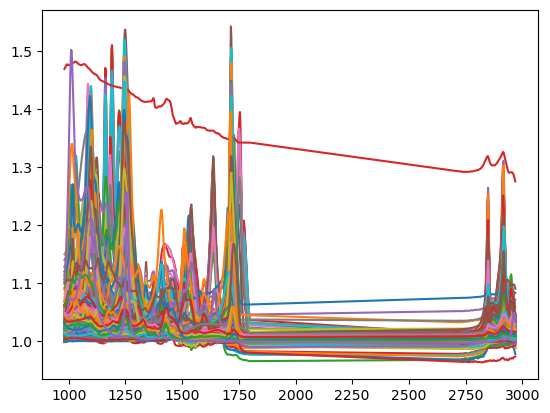

In [32]:
_ = plt.plot(flopp_df.iloc[:,:-4].T)

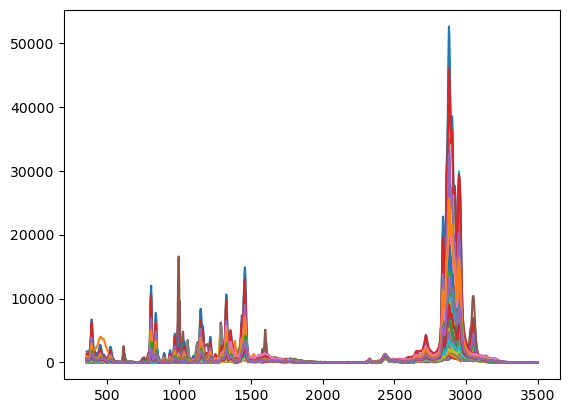

In [33]:
_ = plt.plot(rebecca_df.iloc[:,:-4].T)

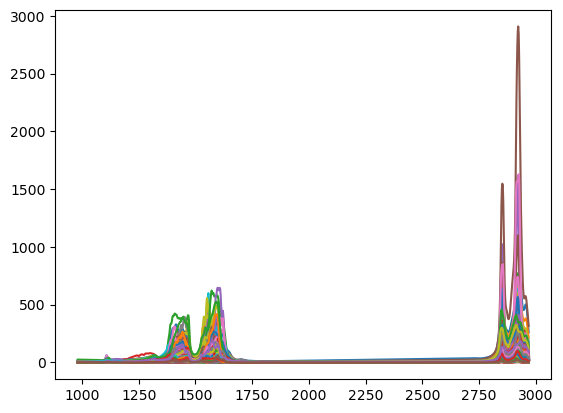

In [34]:
_ = plt.plot(stearates_df.iloc[:,:-5].T)

In [62]:

slopp_df = pd.read_csv('slopp_data_raman_final_specy_non_norm.csv')
del slopp_df['Unnamed: 0']
slopp_df.columns = list(np.float64(slopp_df.columns[:-4])) + list(slopp_df.columns[-4:])
#slopp_df = slopp_df.query('polymer != "Cotton"').reset_index(drop=True)
slopp_df = slopp_df.query('polymer != "Cotton" and polymer !="Dyed Cellulose"').reset_index(drop=True)

rebecca_df = pd.read_csv('rebecca_data_raman_final_specy_non_norm.csv')
del rebecca_df['Unnamed: 0']
rebecca_df.columns = list(np.float64(rebecca_df.columns[:-4])) + list(rebecca_df.columns[-4:])

mIRageLibraySpectra_Removed = pd.read_csv('mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'
rebecca_df = rebecca_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "Raman"')['ID']) for x in rebecca_df['id']])[0],
                             axis=0).reset_index(drop=True)


stearates_df = pd.read_csv('stearates_data_raman_final_specy_non_norm.csv')
del stearates_df['Unnamed: 0']
stearates_df.columns = list(np.float64(stearates_df.columns[:-4])) + list(stearates_df.columns[-4:])


In [64]:
slopp_df['noise'] = slopp_df.iloc[:,:-4].std(1)
slopp_df.iloc[:,-3:].to_csv('noise_ref_lib/noise_slopp.csv')

In [66]:
rebecca_df['noise'] = rebecca_df.iloc[:,:-4].std(1)
rebecca_df.iloc[:,-3:].to_csv('noise_ref_lib/noise_rebecca_raman.csv')

In [68]:
stearates_df['noise'] = stearates_df.iloc[:,:-4].std(1)
stearates_df.iloc[:,-3:].to_csv('noise_ref_lib/noise_stearates_raman.csv')

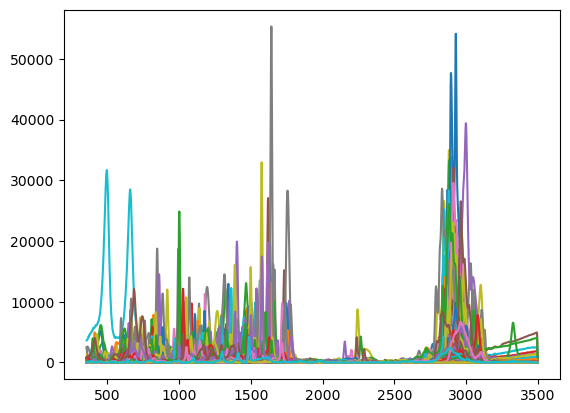

In [45]:
_ = plt.plot(slopp_df.iloc[:,:-4].T)

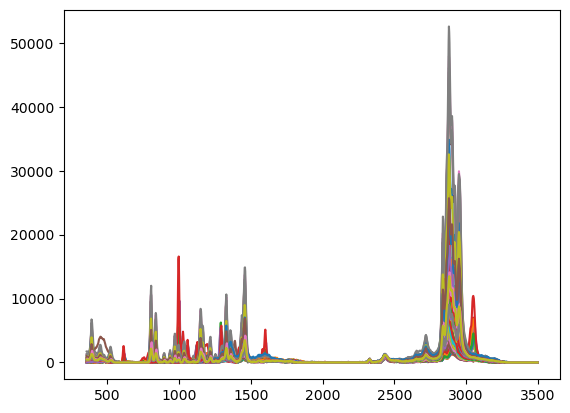

In [46]:
_ = plt.plot(rebecca_df.iloc[:,:-4].T)

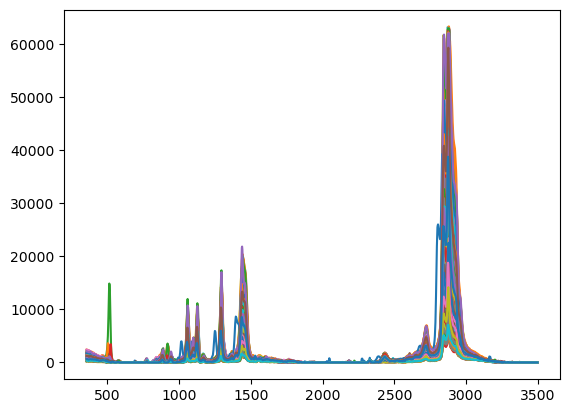

In [47]:
_ = plt.plot(stearates_df.iloc[:,:-4].T)